# Autoclaving – energy demand model

*Thermal activation solid products › Autoclaving* (manuscript Fig. 1)

**Examples** (Fig. 1). All use the same model; the examples change nothing in the equations.
| Process | Products |
|---|---|
| Sterilization | canned food, pet food, pharmaceutical products |
| Hardening | vulcanization, fiber reinforced plastics |
| Boiling small scale | speciality canned vegetables, small scale meat or sea food |

Batch process: product, packaging and autoclave are heated from $T_{start}$ to $T_{steri}$, held there and cooled to $T_{final}$ (manuscript section *Autoclaving*, Fig. 5). The phases run one after another; `duty_basis` chooses whether the pinch analysis gets the power of each phase (manuscript) or the energy per batch spread over the cycle.

$$\dot Q_{heating}=\frac{\sum_i m_i\,c_{p,i}\,(T_{steri}-T_{start})}{t_{heating}}+\frac1t\sum A\,U\,(T_i-T_{amb})\quad(12)$$
$$\dot Q_{cooling}=\frac{\sum_i m_i\,c_{p,i}\,(T_{steri}-T_{final})}{t_{cooling}}-\frac1t\sum A\,U\,(T_i-T_{amb})\quad(13)\qquad \dot Q_{holding}=A\,U\,(T_{steri}-T_{amb})\quad(14)$$

This notebook holds no formulas of its own: it imports **`model.py`**, the model the app runs.

1. Example calculation
2. Figures and simplified P&ID (saved as `pid.svg`)
3. Validation against the manuscript and consistency checks
4. Comparison with an existing implementation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch, Polygon
from IPython.display import display, Markdown

try:
    import process_models
except ImportError:            # not installed: use the copy in this repository
    import sys
    sys.path.insert(0, str(Path.cwd().parents[1]))   # .../process_models (the folder holding the package)

from process_models import PROCESSES, run_process
from process_models.autoclaving.model import MODEL, calculate

KEY = MODEL.key

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def show(res, audit):
    """Input table, results and stream data of one run."""
    display(Markdown("**Inputs** (required / optional, source of each value)"))
    display(pd.DataFrame(audit))
    for w in res.warnings:
        print("WARNING:", w)
    display(Markdown("**Results**"))
    display(pd.DataFrame(res.summary()))
    display(Markdown("**Stream data** (what the app hands to the pinch analysis)"))
    display(pd.DataFrame(res.stream_table()))


print(f"{MODEL.name} v{MODEL.version} | processes found by the app: {list(PROCESSES)}")

Autoclaving v1.0 | processes found by the app: ['autoclaving', 'conductive_drying', 'continuous_bath_heating', 'continuous_heating_of_fluid', 'convective_drying', 'thermal_phase_change']


## 1  Example calculation
Sterilization of canned food. The values are **illustrative, not from the manuscript** (it gives no inputs for its
case): 500 kg product, 100 kg cans, 1,500 kg autoclave, 20 → 121 → 40 °C, 20 / 15 / 20 min, with heat losses.

In [2]:
CANS = dict(m_product=500, cp_product=3.6, m_packaging=100, m_autoclave=1500, T_start=20, T_steri=121, T_final=40,
            t_heating_min=20, t_holding_min=15, t_cooling_min=20, loss_area=12, U_value=1.5)
result, audit = run_process(KEY, **CANS)
show(result, audit)

**Inputs** (required / optional, source of each value)

,Symbol,Input,Value,Unit,Type,Source,Manuscript / note
0,m_product,Mass of product per batch,500.000,kg,required,user input,"Sect. 'Autoclaving', input list"
1,"cp,product",Specific heat capacity of the product,3.600,kJ/(kg K),required,user input,"Sect. 'Autoclaving', input list"
2,m_packaging,Mass of packaging per batch,100.000,kg,required,user input,"Sect. 'Autoclaving', input list | 0 for unpackaged products."
3,m_autoclave,Mass of the autoclave,"1,500.000",kg,required,user input,"Sect. 'Autoclaving', input list"
4,T_start,Initial temperature,20.000,degC,required,user input,"Sect. 'Autoclaving', input list"
5,T_steri,Sterilization (target) temperature,121.000,degC,required,user input,"Sect. 'Autoclaving', input list"
6,T_final,Final temperature after cooling,40.000,degC,required,user input,"Sect. 'Autoclaving', input list"
7,t_heating,Heating time,20.000,min,required,user input,"Sect. 'Autoclaving', input list"
8,t_holding,Holding time,15.000,min,required,user input,"Sect. 'Autoclaving', input list"
9,t_cooling,Cooling time,20.000,min,required,user input,"Sect. 'Autoclaving', input list"


**Results**

,Quantity,Symbol,Value,Unit,Manuscript ref.
0,"Heat capacity of product, packaging, autoclave",sum m_i*cp_i,"2,600.000",kJ/K,-
1,"Heating, sensible",sum m_i*cp_i*(T_steri - T_start)/t_heating,218.833,kW,"Eq. (12), 1st term"
2,Heat losses during heating,(1/t) sum A*U*(T_i - T_amb),0.909,kW,"Eq. (12), 2nd term"
3,HEATING DEMAND (heating phase),Q_heating,219.742,kW,Eq. (12)
4,HOLDING DEMAND (holding phase),A*U*(T_steri - T_amb),1.818,kW,Eq. (14)
5,"Cooling, sensible",sum m_i*cp_i*(T_steri - T_final)/t_cooling,175.500,kW,"Eq. (13), 1st term"
6,Heat losses during cooling,(1/t) sum A*U*(T_i - T_amb),1.089,kW,"Eq. (13), 2nd term (subtracted)"
7,COOLING DEMAND (cooling phase),Q_cooling,174.411,kW,Eq. (13)
8,Heat demand per batch (heating + holding),Q_heating*t_h + Q_holding*t_hold,265.327,MJ,-
9,Cooling energy per batch,Q_cooling*t_c,209.293,MJ,-


**Stream data** (what the app hands to the pinch analysis)

,stream,type,T_supply_degC,T_target_degC,CP_kW_per_K,Q_kW
0,batch heating,cold,20.000,121.000,2.176,219.742
1,holding,cold,121.000,122.000,1.818,1.818
2,batch cooling,hot,121.000,40.000,2.153,174.411


## 2  Figures and simplified P&ID

In [3]:
def plot_demand_breakdown(res):
    """Every kW quantity of the results table; totals dark."""
    rows = [r for r in res.summary() if r["Unit"] == "kW"][::-1]
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(rows) + 1.4))
    colors = ["#333333" if r["Quantity"].split(" (")[0].isupper() else "#4c78a8" for r in rows]
    bars = ax.barh([r["Quantity"] for r in rows], [r["Value"] for r in rows], color=colors)
    for b, r in zip(bars, rows):
        ax.annotate(f"{r['Value']:,.1f} kW", (b.get_width(), b.get_y() + b.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set(xlabel="Thermal power [kW]", title=f"Energy demand: {MODEL.name}")
    ax.margins(x=0.2)
    fig.tight_layout()
    return fig


def plot_stream_data(res):
    """Streams handed to the pinch analysis, stacked by heat flow: cold blue, hot red."""
    fig, ax = plt.subplots(figsize=(8, 4.6))
    q, temps = {"cold": 0.0, "hot": 0.0}, []
    for s in res.stream_table():
        q0 = q[s["type"]]
        q[s["type"]] = q1 = q0 + s["Q_kW"]
        color = "tab:blue" if s["type"] == "cold" else "tab:red"
        ax.annotate("", xy=(q1, s["T_target_degC"]), xytext=(q0, s["T_supply_degC"]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=14))
        ax.text((q0 + q1) / 2, (s["T_supply_degC"] + s["T_target_degC"]) / 2, "  " + s["stream"],
                color=color, fontsize=8, va="bottom")
        temps += [s["T_supply_degC"], s["T_target_degC"]]
    qmax = max(q.values()) or 1.0
    ax.set_xlim(-0.02 * qmax, 1.1 * qmax)
    ax.set_ylim(min(temps) - 10, max(temps) + 10)
    ax.set(xlabel="Heat flow [kW]", ylabel="Temperature [degC]", title="Stream data (cold: blue, hot: red)")
    fig.tight_layout()
    return fig


def plot_sensitivity(res, sweeps):
    """One-at-a-time sensitivity of the heating and cooling demand."""
    fig, axes = plt.subplots(1, len(sweeps), figsize=(6 * len(sweeps), 4), squeeze=False)
    for ax, (param, grid, xlabel) in zip(axes[0], sweeps):
        rows = []
        for x in grid:
            try:
                r = calculate({**res.inputs, param: float(x)})
                rows.append((x, r.Q_heating, r.Q_cooling))
            except ValueError:
                continue
        xs, qh, qc = zip(*rows)
        ax.plot(xs, qh, label="heating demand")
        if any(qc):
            ax.plot(xs, qc, label="cooling demand")
        ax.axvline(res.inputs[param], color="grey", ls="--", lw=0.8)
        ax.set(xlabel=xlabel, ylabel="Thermal power [kW]")
        ax.legend(fontsize=8)
    fig.suptitle("Sensitivity (one parameter varied, all others fixed)")
    fig.tight_layout()
    return fig



SWEEPS = [("t_heating_min", np.linspace(5, 60, 23), "Heating time [min]"),
          ("T_steri", np.linspace(100, 140, 21), "Sterilization temperature [degC]")]

In [4]:
class Sketch:
    """Small drawing kit for the simplified P&IDs (ISA-5.1 style tags)."""

    def __init__(self, ax, lw=1.8):
        self.ax, self.lw = ax, lw

    def line(self, xs, ys, ls="-", lw=None, color="k"):
        self.ax.plot(xs, ys, ls=ls, lw=lw or self.lw, color=color, solid_capstyle="butt", zorder=2)

    def arrow(self, x0, y0, x1, y1, color="k"):
        self.ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=3,
                         arrowprops=dict(arrowstyle="-|>", lw=self.lw, color=color, mutation_scale=14))

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", 9); kw.setdefault("ha", "center"); kw.setdefault("va", "center")
        self.ax.text(x, y, s, **kw)

    def hx(self, x, y, r=0.55):
        """Heat exchanger: circle with zigzag."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.6, zorder=4))
        self.ax.plot(np.linspace(x - 0.42, x + 0.42, 7), y + 0.14 * np.array([0, 1, -1, 1, -1, 1, 0]),
                     color="k", lw=1.3, zorder=5)

    def box(self, x, y, w, h, s="", fc="#eef3f8", rounded=False, fontsize=8.5):
        patch = (FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.3", fc=fc, ec="k", lw=1.6, zorder=3)
                 if rounded else Rectangle((x, y), w, h, fc=fc, ec="k", lw=1.6, zorder=3))
        self.ax.add_patch(patch)
        if s:
            self.text(x + w / 2, y + h / 2, s, fontsize=fontsize, zorder=4)

    def pump(self, x, y, tag, r=0.45):
        """Pump or fan."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.6, zorder=4))
        self.ax.add_patch(Polygon([(x - .2, y - .28), (x - .2, y + .28), (x + .3, y)], fc="k", zorder=5))
        self.text(x, y - r - 0.3, tag)

    def bubble(self, x, y, tag, num, value=None, r=0.42, below=False):
        """Instrument bubble with tag, loop number and the value it measures or controls."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.4, zorder=5))
        self.text(x, y + 0.1, tag, fontsize=8.5, fontweight="bold", zorder=6)
        self.text(x, y - 0.16, num, fontsize=8, zorder=6)
        if value is not None:
            self.text(x, y - r - 0.25 if below else y + r + 0.25, value, color="firebrick", fontweight="bold")

    def valve_h(self, x, y):
        """Control valve on a horizontal line, actuator on top."""
        for sgn in (+1, -1):
            self.ax.add_patch(Polygon([(x + sgn * .22, y + .25), (x + sgn * .22, y - .25), (x, y)],
                                      fc="white", ec="k", lw=1.4, zorder=5))
        self.ax.plot([x, x], [y, y + 0.45], color="k", lw=1.2, zorder=5)
        self.ax.add_patch(Circle((x, y + 0.65), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    def valve_v(self, x, y, side=+1):
        """Control valve on a vertical line, actuator to the side."""
        for sgn in (+1, -1):
            self.ax.add_patch(Polygon([(x - .25, y + sgn * .22), (x + .25, y + sgn * .22), (x, y)],
                                      fc="white", ec="k", lw=1.4, zorder=5))
        self.ax.plot([x, x + side * 0.45], [y, y], color="k", lw=1.2, zorder=5)
        self.ax.add_patch(Circle((x + side * 0.65, y), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    def signal(self, xs, ys):
        self.line(xs, ys, ls=":", lw=1.1)


FOOT = "Simplified P&ID (ISA-5.1 style tags), generated from the demand model - not for construction."


def new_pid(title, ymin=-1.3, ymax=9.6):
    fig, ax = plt.subplots(figsize=(16, 16 * (ymax - ymin) / 20))
    ax.set_xlim(0, 20); ax.set_ylim(ymin, ymax); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=12)
    return fig, ax, Sketch(ax)


def footer(ax, s):
    ax.text(0.3, ax.get_ylim()[0] + 0.05, s, fontsize=8.5, color="dimgrey", va="bottom")

In [5]:
def draw_pid(res):
    """Simplified P&ID of a steam autoclave with cooling water and drain."""
    v = res.inputs
    fig, ax, s = new_pid("Autoclaving (batch sterilization) - simplified P&ID")
    ax.add_patch(FancyBboxPatch((5.0, 2.4), 7.0, 3.2, boxstyle="round,pad=0.0,rounding_size=1.2",
                                fc="white", ec="k", lw=1.8, zorder=3))
    for xb in (6.0, 7.9, 9.8):
        ax.add_patch(Rectangle((xb, 2.9), 1.5, 1.6, fc="#f3e3d3", ec="k", lw=1.0, hatch="//", zorder=4))
    s.text(8.5, 5.05, f"A-101 Autoclave: product {v['m_product']:,.0f} kg + packaging {v['m_packaging']:,.0f} kg", zorder=5)
    # ---- steam in --------------------------------------------------------------------------------
    s.line([1.6, 6.2], [7.0, 7.0]); s.line([6.2, 6.2], [7.0, 5.6]); s.arrow(2.4, 7.0, 2.8, 7.0)
    s.valve_h(4.0, 7.0); s.text(4.0, 6.55, "TV-101", fontsize=8)
    s.text(0.3, 7.4, "steam / hot utility in" + (f", {v['T_utility_in']:.0f} degC" if v["T_utility_in"] is not None else ""),
           ha="left", fontsize=7.5)
    # ---- cooling water in --------------------------------------------------------------------------
    s.line([15.4, 10.8], [7.0, 7.0]); s.line([10.8, 10.8], [7.0, 5.6]); s.arrow(14.6, 7.0, 14.2, 7.0)
    s.valve_h(13.0, 7.0); s.text(13.0, 6.55, "TV-102", fontsize=8)
    s.text(15.5, 7.4, "cooling water in", ha="left", fontsize=7.5)
    s.signal([8.5, 8.5], [5.6, 6.4]); s.bubble(8.5, 6.82, "TIC", "101", f"T_steri = {v['T_steri']:.0f} degC")
    # ---- drain --------------------------------------------------------------------------------------
    s.line([8.5, 8.5], [2.4, 1.2]); s.line([8.5, 13.6], [1.2, 1.2]); s.valve_h(11.0, 1.2); s.arrow(12.4, 1.2, 12.8, 1.2)
    s.text(13.7, 1.2, "condensate / cooling water out", ha="left", fontsize=7.5)
    # ---- duties --------------------------------------------------------------------------------------
    s.box(13.3, 2.4, 6.4, 3.0, fc="white")
    s.text(13.5, 3.9, f"Heating, Eq. (12): {res.Q_heating:,.1f} kW for {v['t_heating_min']:g} min\n"
           f"Holding, Eq. (14): {res.Q_holding:,.1f} kW for {v['t_holding_min']:g} min\n"
           f"Cooling, Eq. (13): {res.Q_cooling:,.1f} kW for {v['t_cooling_min']:g} min\n"
           f"Heat demand per batch: {res.E_demand_MJ:,.1f} MJ\n"
           f"{v['T_start']:g} -> {v['T_steri']:g} -> {v['T_final']:g} degC, cycle {res.t_cycle_min:g} min",
           ha="left", fontsize=8.5)
    footer(ax, FOOT + " Batch: heating, holding and cooling run one after another.\n"
           f"Heat capacity of product, packaging and autoclave: {res.heat_capacity_kJ_K:,.0f} kJ/K; "
           f"losses A*U = {v['loss_area'] * v['U_value']:,.1f} W/K")
    return fig

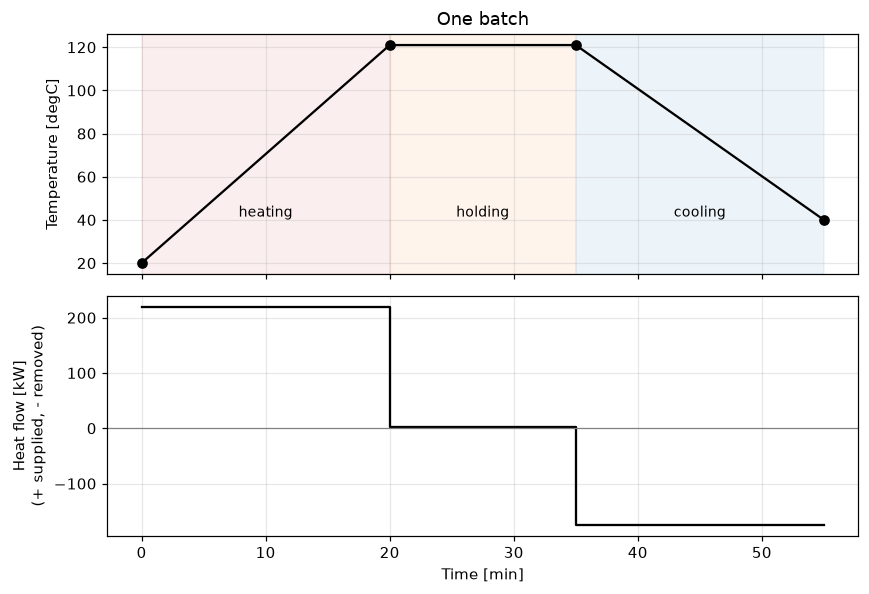

In [6]:
def plot_profile(res):
    """Temperature and heat flow over one batch (like Fig. 5)."""
    v = res.inputs
    t1, t2, t3 = v["t_heating_min"], v["t_heating_min"] + v["t_holding_min"], res.t_cycle_min
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
    a1.plot([0, t1, t2, t3], [v["T_start"], v["T_steri"], v["T_steri"], v["T_final"]], "k-o")
    for x0, x1, label in ((0, t1, "heating"), (t1, t2, "holding"), (t2, t3, "cooling")):
        a1.axvspan(x0, x1, alpha=0.08, color={"heating": "tab:red", "holding": "tab:orange", "cooling": "tab:blue"}[label])
        a1.text((x0 + x1) / 2, v["T_final"], label, ha="center", va="bottom", fontsize=9)
    a1.set(ylabel="Temperature [degC]", title="One batch")
    a2.step([0, t1, t2, t3], [res.Q_heating, res.Q_holding, -res.Q_cooling, -res.Q_cooling], where="post", color="k")
    a2.axhline(0, color="grey", lw=0.8)
    a2.set(xlabel="Time [min]", ylabel="Heat flow [kW]\n(+ supplied, - removed)")
    fig.tight_layout()
    return fig


plot_profile(result)
plt.show()

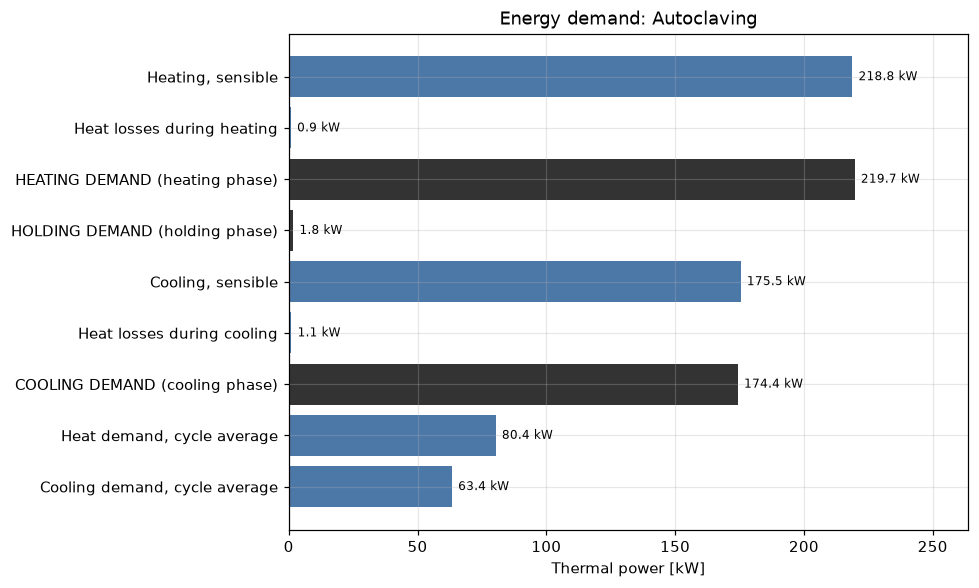

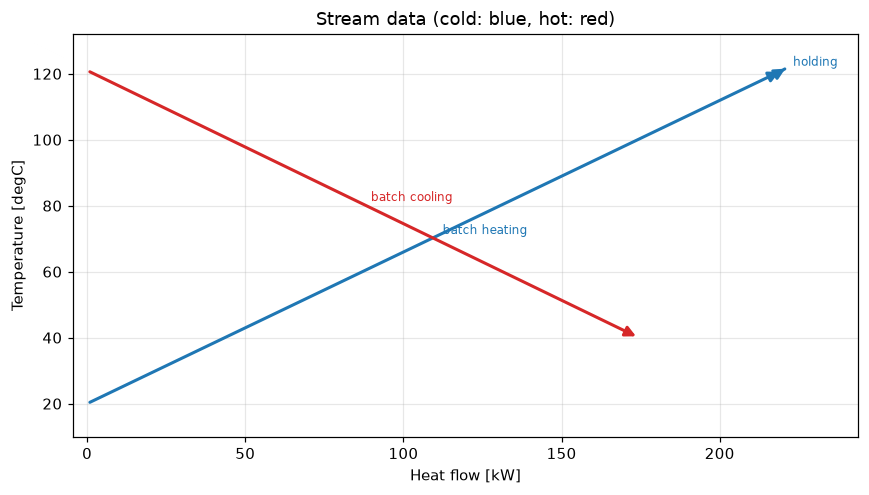

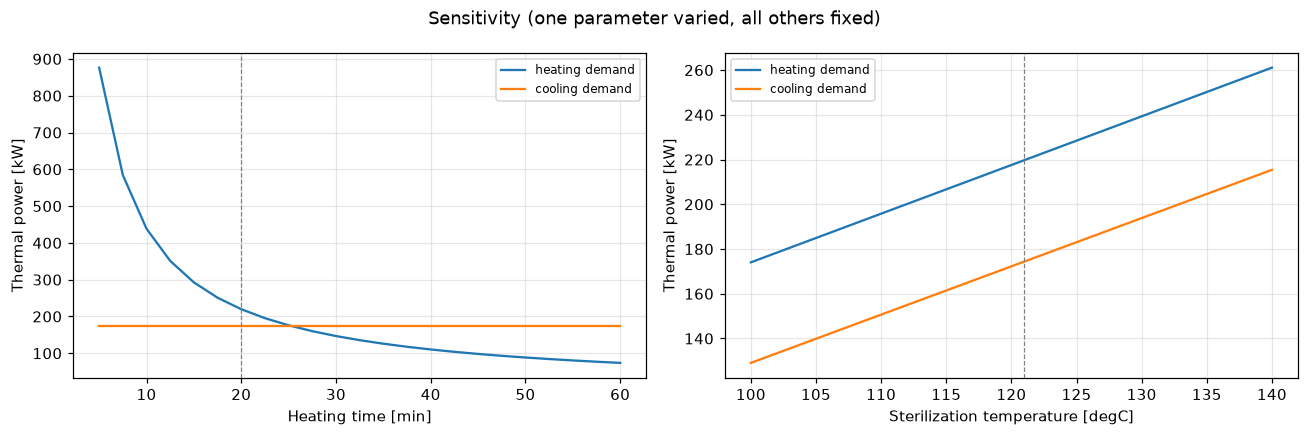

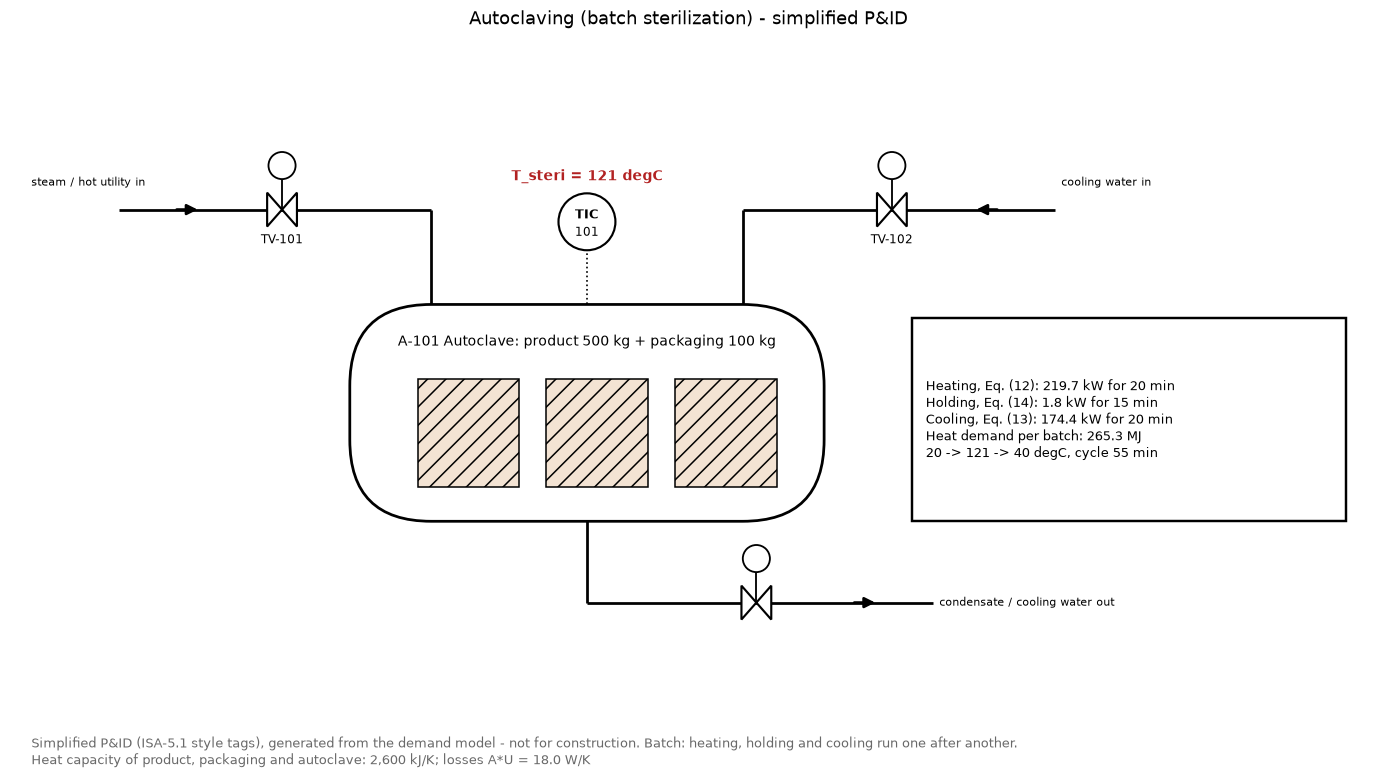

In [7]:
for fig in (plot_demand_breakdown(result), plot_stream_data(result), plot_sensitivity(result, SWEEPS)):
    plt.show()

fig = draw_pid(result)
fig.savefig("pid.svg", bbox_inches="tight")   # P&ID of the example, kept next to model.py
plt.show()

## 3  Validation against the manuscript
Batch sterilization, reference data of O'Callaghan et al. (reference [25]), manuscript p. 18:
modelled 62.65 MJ, reference 63.18 MJ, RMSE 0.53 MJ, relative deviation 0.85 %.

**Points found in the manuscript (please check):**
1. **No inputs are given** for this case (masses, heat capacities, temperatures, times, losses), so the 62.65 MJ
   cannot be recalculated. The legacy `classes.BatchSterilizationModel` or its example would close this gap.
2. Whether 62.65 MJ is heating only or heating + holding per batch is not stated (the results table gives both).
3. $T_i$ in the loss terms of Eq. (12)/(13) is not defined; here the mean temperature of the phase (linear profile).
4. The utility mass flow and inlet temperature are listed as inputs but are not in Eq. (12)–(14).
5. 0.85 % refers to the model value (0.53 / 62.65); relative to the reference it is 0.84 %.

In [8]:
REF = dict(E_model=62.65, E_ref=63.18, RMSE=0.53)
dev = abs(REF["E_model"] - REF["E_ref"])
print(f"|model - reference| = {dev:.2f} MJ (manuscript RMSE {REF['RMSE']}); "
      f"{dev / REF['E_model']:.2%} of the model value, {dev / REF['E_ref']:.2%} of the reference")
assert abs(dev - REF["RMSE"]) < 1e-9

# ---- consistency checks -----------------------------------------------------------------------
C = 500 * 3.6 + 100 * 0.5 + 1500 * 0.5
AU = 12 * 1.5 / 1000
assert abs(result.Q_heating - (C * 101 / 1200 + AU * (70.5 - 20))) < 1e-9          # Eq. (12) by hand
assert abs(result.Q_cooling - (C * 81 / 1200 - AU * (80.5 - 20))) < 1e-9           # Eq. (13) by hand
assert abs(result.Q_holding - AU * 101) < 1e-9                                      # Eq. (14) by hand
# energy balance over a batch: heat in - heat out = losses (the autoclave ends 20 K above its start)
balance = result.E_demand_MJ - result.E_cooling_MJ
assert abs(balance - (C * (40 - 20) / 1000 + (result.Q_loss_heating * 1200 + result.Q_holding * 900 + result.Q_loss_cooling * 1200) / 1000)) < 1e-9
cyc, _ = run_process(KEY, **CANS, duty_basis="cycle")
assert abs(sum(s["Q_kW"] for s in cyc.stream_table() if s["type"] == "cold") * 55 * 60 / 1000 - cyc.E_demand_MJ) < 1e-9
print("All consistency checks passed.")
display(pd.DataFrame(cyc.stream_table()))

|model - reference| = 0.53 MJ (manuscript RMSE 0.53); 0.85% of the model value, 0.84% of the reference
All consistency checks passed.


,stream,type,T_supply_degC,T_target_degC,CP_kW_per_K,Q_kW
0,batch heating,cold,20.000,121.000,0.791,79.906
1,holding,cold,121.000,122.000,0.496,0.496
2,batch cooling,hot,121.000,40.000,0.783,63.422


## 4  Comparison with an existing implementation
Not possible yet: the original notebook (`continuous_heating_of_fluid/energy_demand_models_notebook_1.ipynb`) only lists
this process as *planned*. The legacy `classes.BatchSterilizationModel` it mentions (fixed −24 K on the product,
no loss terms, cooling energy not returned) is not in the repository.